# Synthetic biomarker benchmark — VascX

This notebook is one of three, one per **lineage** of biomarker software, beside a
[summary notebook](biomarker-synthetic.ipynb) that compares the three over the catalogue's own
names. It reads the evidence of one run of the benchmark and argues about what it shows for this
group alone: `vascx`.

**VascX** shares no code with either of the other groups: it reimplements every biomarker it computes. It stands alone, so nothing in this notebook compares it with a sibling; the comparison with the other groups is in the [summary notebook](biomarker-synthetic.ipynb).

## What this benchmark is

**It measures over synthetically generated segmentations**: drawn arteries, veins, an optic disc
and an optic cup, not photographs. No eye was photographed and no annotator was consulted. The
shapes, and what each one settles, are in the
[shapes notebook](biomarker-synthetic-shapes.ipynb).

**There are two kinds of benchmarking here, and they are different questions.**

1. **Sensitivity to rotation.** The same shape is drawn at seven angles, every 15° of a quarter
   turn. The geometry is identical at each, so anything that moves is the implementation or the
   pixel grid. This needs no ground truth: it is a self-consistency check, and an implementation
   can fail it while agreeing with the ground truth on average.
2. **Agreement with ground truth.** The ground truth is a theoretical value derived from the
   geometry before anything was drawn, stored beside the images, not an annotation and not
   another program's output. There are two:
   - **by canonical name**, for every column an adapter maps onto the catalogue, using the
     definition the catalogue records for that biomarker (the paper that introduced it, where
     there is one);
   - **by the program's own description**, for the columns the catalogue cannot name: what the
     column's name, docstring or cited paper says it computes, worked out on the same geometry
     (`src/benchmarks/shapes/claims.py`). This is how a column like PVBM's tortuosity index is
     checked at all.

**How to read the tables.** Rows are columns **under the names this lineage's own project gives
them** — VascX's — with each sibling's column on the row of the VascX column it is a rewrite of
(`se.native`); a column with no VascX counterpart keeps its own name, with its implementation's
after it. The last column, **canonical**, says which catalogued biomarker each row answers to, and
where siblings pool it differently, each one's. Columns are this group's implementations, in
lineage order. Where a quantity was measured on several shapes or
at several angles, the cell is the **worst** of them, because a mean would hide the case that
matters. Percentages are of the required value. A difference smaller than 1% of a biomarker's own
size is treated as no difference: that is the pixel grid's floor, argued in the summary notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_synthetic as benchmark  # noqa: E402
from benchmarks import synthetic_evidence as se  # noqa: E402
from benchmarks.shapes import claims  # noqa: E402

#: This notebook's group, from the benchmark's own declaration, in lineage order.
GROUP = "vascx"
IMPLEMENTATIONS = list(benchmark.GROUPS[GROUP])

#: The two reporting thresholds. Neither is a standard anybody agreed: they decide which rows a
#: table shows, not whether anything passes. Nothing passes or fails here.
ROTATION_TOLERANCE = se.ROTATION_TOLERANCE
GROUND_TRUTH_TOLERANCE = se.GROUND_TRUTH_TOLERANCE

EVIDENCE = se.read(IMPLEMENTATIONS, ROOT)
AGAINST = se.agreement(EVIDENCE)
CLAIMED = se.claimed_agreement(EVIDENCE)

#: Every table is indexed by each column's name in this lineage's own project (`se.native`), and
#: carries the canonical name it answers to as its last column.
ROW = "native"
COMMENTS = se.comments(EVIDENCE)


def commented(table):
    # A table indexed by native name, with the canonical name each row answers to appended.
    shown = table.copy()
    rows = shown.index.get_level_values(ROW) if ROW in (shown.index.names or []) else shown.index
    shown["canonical"] = COMMENTS.reindex(rows).fillna("—").values
    return shown
pd.set_option("display.width", 200, "display.max_rows", 300, "display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})


def heading(text: str) -> None:
    display(Markdown(text))


print(
    f"{len(EVIDENCE.said):,} numbers from {len(IMPLEMENTATIONS)} implementation(s) × "
    f"{len(EVIDENCE.shapes)} shapes × {EVIDENCE.said['rotation'].nunique()} angles; "
    f"{len(AGAINST):,} judged by canonical name and {len(CLAIMED):,} by their own description"
)

12,012 numbers from 1 implementation(s) × 13 shapes × 7 angles; 153 judged by canonical name and 1,144 by their own description


## 1. Coverage — how much there is, and how much of it can be judged

How many columns each implementation returns, how many of them carry a canonical name, and what
happens to the rest. A column with no canonical name is still checked here when the shapes can
settle what its own description says it computes; the last two rows say how many can and cannot.

In [2]:
se.coverage(EVIDENCE)

,vascx
columns it returns,132.0
…that returned a value,115.0
matching a canonical name,6.0
"…of those, returning a value",6.0
"unnamed, but returning a value",109.0
…held to their own description,20.0
…whose description the shapes cannot settle,89.0
seconds per image,9.3


### 1.1 The columns with no canonical name, and what each claims

Every column the catalogue cannot name, with what its authors say it computes and where they say
it. Those marked *cannot be settled* are claims the shapes have no value for (most need a fovea,
which no shape places); they are measured and stored, and checked only for rotation in §3.2.

In [3]:
rows = []
for slug in IMPLEMENTATIONS:
    mine = claims.claimed(slug)
    for own, name in EVIDENCE.names[slug].items():
        if name:
            continue
        claim = mine.get(own)
        rows.append(
            {
                "implementation": slug,
                "its own name": own,
                "claims to compute": claim.claims if claim else "—",
                "held to": (
                    claim.canonical or "a value derived from the geometry"
                    if claim and not claim.unsettled
                    else ("cannot be settled: " + claim.unsettled if claim else "not claimed")
                ),
            }
        )
UNNAMED = pd.DataFrame(rows)
UNNAMED if len(UNNAMED) else print("every column it returns has a canonical name")

,implementation,its own name,claims to compute,held to
0,vascx,lw_tort_dist_max_segment_len_0p15_crcl_multiplier_1p16666666667_full_arteries,"arc over chord, length-weighted, with segments capped at another length",tortuosity/hart-tau1/artery/length-weighted
1,vascx,lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_arteries,"arc over chord, length-weighted, with segments capped at another length",tortuosity/hart-tau1/artery/length-weighted
2,vascx,lw_tort_curv_crcl_multiplier_1p16666666667_full_arteries,"mean curvature along a spline, times the disc-to-fovea distance","cannot be settled: it needs a fovea, and the synthetic shapes place none"
3,vascx,vd_crcl_multiplier_1p16666666667_full_arteries,"vessel area over the area of its disc-centred circle, 1.1667 disc diameters",a value derived from the geometry
4,vascx,median_temporal_angle_arteries,the angle the temporal arcades open at,"cannot be settled: it needs a fovea, and the synthetic shapes place none"
5,vascx,lw_tort_dist_max_segment_len_0p15_crcl_multiplier_1p16666666667_full_veins,"arc over chord, length-weighted, with segments capped at another length",tortuosity/hart-tau1/vein/length-weighted
6,vascx,lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_veins,"arc over chord, length-weighted, with segments capped at another length",tortuosity/hart-tau1/vein/length-weighted
7,vascx,lw_tort_curv_crcl_multiplier_1p16666666667_full_veins,"mean curvature along a spline, times the disc-to-fovea distance","cannot be settled: it needs a fovea, and the synthetic shapes place none"
8,vascx,vd_crcl_multiplier_1p16666666667_full_veins,"vessel area over the area of its disc-centred circle, 1.1667 disc diameters",a value derived from the geometry
9,vascx,median_temporal_angle_veins,the angle the temporal arcades open at,"cannot be settled: it needs a fovea, and the synthetic shapes place none"


## 2. Hard failures — what raised, and on what

Every exception an adapter caught, and every rendering nothing came back for: which quantity,
which shape, which angle. A failure is not a bad measurement: an implementation that raises has
said it could not answer, and one that returns a confident wrong number has not.

In [4]:
TROUBLES = se.troubles(EVIDENCE)
print(f"{len(TROUBLES)} exceptions over {EVIDENCE.said['key'].nunique()} renderings")
TROUBLES

0 exceptions over 91 renderings


,implementation,shape,rotation,what it could not answer,what it raised


## 3. Sensitivity to rotation

The geometry is identical at every angle, so any spread is the implementation or the grid. Each
cell is the **worst spread a quantity showed on any one shape**, max minus min over the seven
angles as a percentage of its mean there. The vertical and horizontal cup-to-disc ratios are left
out: they are read along the image's axes, so turning the photograph is meant to move them.

### 3.1 The columns with a canonical name

In [5]:
ROTATION = se.rotation(EVIDENCE, named=True, by=ROW).unstack("implementation")
ROTATION = EVIDENCE.in_order(ROTATION)
unsteady = se.over(ROTATION, ROTATION_TOLERANCE)
print(
    f"{len(unsteady)} of {len(ROTATION)} named columns move by more than "
    f"{ROTATION_TOLERANCE:.0%} somewhere; worst shape:"
)
commented(se.legible(unsteady))

2 of 6 named columns move by more than 10% somewhere; worst shape:


implementation,vascx,canonical
native,,
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_arteries,12.8%,tortuosity/hart-tau1/artery/length-weighted
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_veins,10.4%,tortuosity/hart-tau1/vein/length-weighted


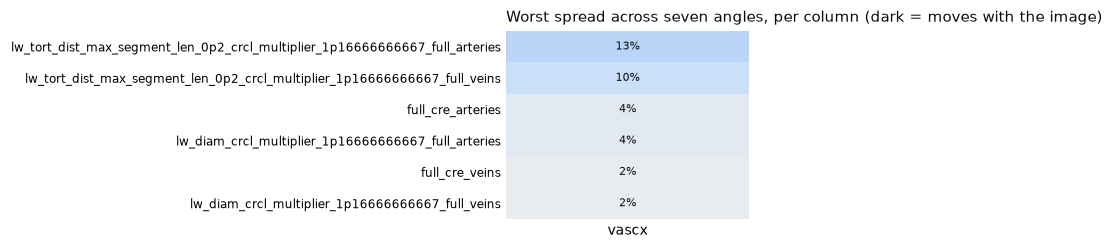

In [6]:
if len(ROTATION):
    shown = ROTATION.loc[ROTATION.max(axis=1).sort_values(ascending=False).index]
    se.heat(
        shown,
        "Worst spread across seven angles, per column (dark = moves with the image)",
        cap=0.5,
    )
    plt.show()

### 3.2 The columns with no canonical name

The same check on every unnamed column. Nothing can compare these with a definition, but they are
as capable of turning with the image as anything else, and nothing else would notice.

In [7]:
OWN_ROTATION = se.rotation(EVIDENCE, named=False, by=ROW)
if OWN_ROTATION.empty:
    print("nothing unnamed to check")
else:
    table = OWN_ROTATION.rename("worst spread").to_frame()
    moving = table[table.iloc[:, 0] > ROTATION_TOLERANCE]
    print(
        f"{len(moving)} of {len(table)} unnamed columns move by more than {ROTATION_TOLERANCE:.0%}"
    )
    display(se.legible(moving.sort_values("worst spread", ascending=False)))

36 of 109 unnamed columns move by more than 10%


worst spread
implementation native                                                                                       
vascx          vd_hf_superior_veins                                                                   700.0%
               vd_crcl_multiplier_1p16666666667_superior_arteries                                     700.0%
               vd_hf_inferior_veins                                                                   700.0%
               vd_hf_superior_arteries                                                                700.0%
               vd_crcl_multiplier_1p16666666667_inferior_veins                                        700.0%
               vd_crcl_multiplier_1p16666666667_superior_veins                                        700.0%
               vd_hf_inferior_arteries                                                                535.9%
               lw_tort_curv_arteries                                                                  504.7%
               lw_tort_curv_crcl_multiplier_1p16666666667_full_arteries                               493.6%
               lw_tort_curv_disc_full_veins                                                           477.9%
               lw_tort_curv_disc_full_arteries                                                        477.7%
               vd_crcl_multiplier_1p16666666667_inferior_arteries                                     407.0%
               md_tort_curv_arteries                                                                  352.2%
               md_tort_curv_veins                                                                     348.5%
               lw_tort_curv_veins                                                                     332.4%
               lw_tort_curv_crcl_multiplier_1p16666666667_full_veins                                  232.9%
               lw_tort_curv_etdrs_full_arteries                                                       169.0%
               lw_tort_curv_crcl_multiplier_1p16666666667_superior_arteries                           139.6%
               lw_tort_curv_crcl_multiplier_1p16666666667_temporal_arteries                           124.6%
               lw_tort_curv_crcl_multiplier_1p16666666667_temporal_veins                               72.3%
               lw_tort_curv_crcl_multiplier_1p16666666667_inferior_veins                               71.7%
               lw_tort_curv_etdrs_full_veins                                                           53.1%
               median_temporal_angle_arteries                                                          46.5%
               median_temporal_angle_veins                                                             37.0%
               md_diam_hf_inferior_arteries                                                            27.5%
               mean_sparsity_etdrs_full_vessels                                                        22.1%
               vd_crcl_multiplier_1p16666666667_nasal_veins                                            19.4%
               vd_crcl_multiplier_1p16666666667_temporal_veins                                         18.7%
               mean_sparsity_elps_full_vessels                                                         18.2%
               md_diam_hf_superior_arteries                                                            18.0%
               lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_veins              15.6%
               md_tort_dist_veins                                                                      14.4%
               lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_arteries           13.0%
               lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_temporal_arteries        12.8%
               lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_temporal_veins           10.4%
               lw_tort_dist_max_segment_len_0p2_crcl_multiplier

### 3.3 Shape by shape, for what moves by more than half

For each implementation, every column — named or not, under VascX's own names — whose spread
across the seven angles is **more than 50%** on at least one shape, against every shape. A row dark
on one shape and light on the rest is a column that one geometry upsets; a row dark everywhere moves
with the picture whatever is drawn. Blank is a shape the column gave no number on.

#### 3.3.1 vascx — 22 of 109 columns move by more than 50%

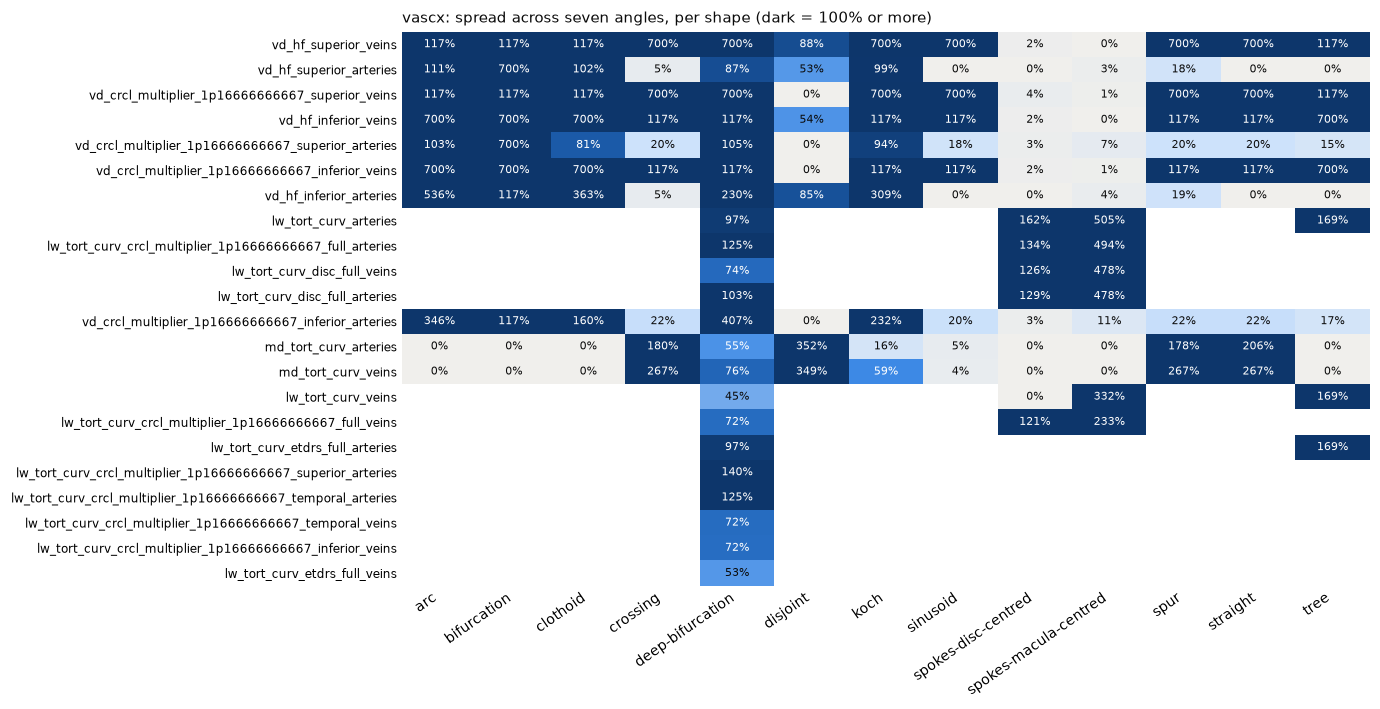

In [8]:
BY_SHAPE = se.rotation_by_shape(EVIDENCE, by=ROW)
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    mine = BY_SHAPE[BY_SHAPE["implementation"] == slug].pivot_table(
        index=ROW, columns="shape", values="spread", aggfunc="max"
    )
    mine = mine.reindex(columns=EVIDENCE.shapes)
    wide = mine[mine.max(axis=1) > 0.5]
    heading(f"#### 3.3.{number} {slug} — {len(wide)} of {len(mine)} columns move by more than 50%")
    if wide.empty:
        print("no column moves by more than 50% on any shape")
        continue
    wide = wide.loc[wide.max(axis=1).sort_values(ascending=False).index]
    se.heat(wide, f"{slug}: spread across seven angles, per shape (dark = 100% or more)")
    plt.show()

**What the maps show.** Two families account for every dark row. VascX's named
distance tortuosity, the columns the catalogue maps onto Hart's τ1, is not among them: its worst
spread is 12.8% (§3.1).

- **Density split into superior and inferior halves** (`vd_hf_*` and the `vd_crcl_*` columns
  ending in `_superior_`/`_inferior_`). The 117% and 700% cells are the signature of a whole
  vessel changing sides. 700% is one angle out of seven with a value, and 117% is six. On the
  straight shape the vein's density is 0.0075 in the inferior half at 0–75°, then 0 there and
  0.0075 in the superior half at 90°. The halves did not turn with the picture at that angle. The
  density of the whole field does not move, and both spokes shapes, which have vessels in every
  direction, stay under 12%.
- **Curvature tortuosity** (`md_tort_curv_*`, `lw_tort_curv_*`). On the straight shape the median
  curvature tortuosity of the artery is 0.19 at 0°, almost 0 at 30–60°, and 0.07 at 90°: a
  straight vessel reads as curved when it lies *along* the image's axes. On the macula-centred
  spokes, `lw_tort_curv_arteries` is about 0.003 at six angles and 0.41 at 60°. On the deep
  bifurcation, every regional variant moves by 45–140%.

Nothing else VascX returns moves by more than half on any shape: 87 of its 109 columns.

## 4. Agreement with ground truth, by canonical name

Every named measurement against the value the catalogue's definition requires of that shape.

### 4.1 The worst disagreement, over every shape and angle

In [9]:
EVERYWHERE = EVIDENCE.in_order(
    AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
)
faults = se.over(EVERYWHERE, GROUND_TRUTH_TOLERANCE)
print(
    f"{len(AGAINST):,} measurements over {AGAINST[ROW].nunique()} named columns; "
    f"{len(faults)} are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere. Worst:"
)
commented(se.legible(faults.loc[faults.max(axis=1).sort_values(ascending=False).index]))

153 measurements over 6 named columns; 2 are out by more than 25% somewhere. Worst:


implementation,vascx,canonical
native,,
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_arteries,43.5%,tortuosity/hart-tau1/artery/length-weighted
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_veins,43.4%,tortuosity/hart-tau1/vein/length-weighted


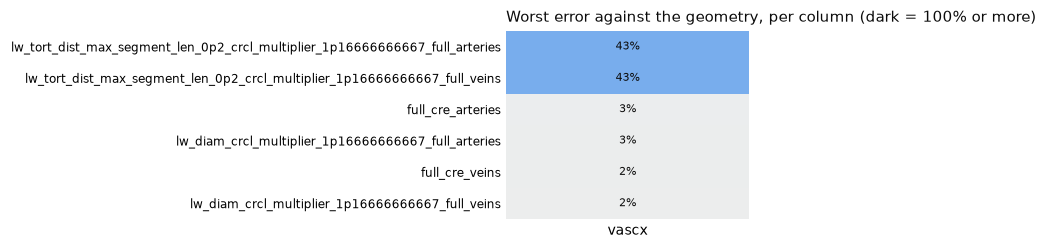

In [10]:
shown = EVERYWHERE.loc[EVERYWHERE.max(axis=1).sort_values(ascending=False).index]
se.heat(shown, "Worst error against the geometry, per column (dark = 100% or more)")
plt.show()

### 4.2 Where the errors fall

Every measurement of a biomarker that is out of tolerance somewhere, as one dot per shape and
angle, signed: right of the line the program said more than the geometry requires, left of it less.
The shaded band is the 25% tolerance. A tight cluster away from nought is a formula; a scatter is
the grid or the shape.

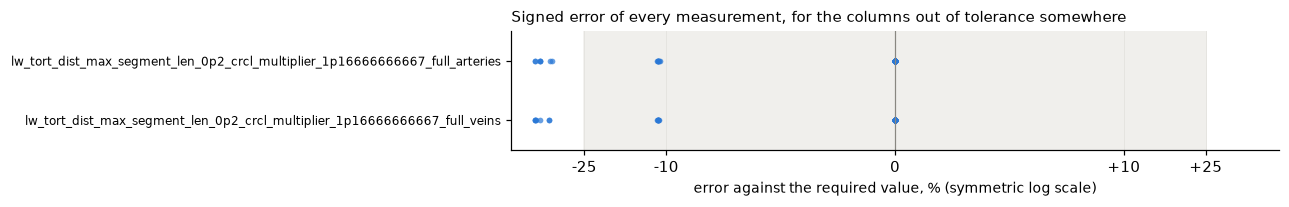

In [11]:
order = list(faults.max(axis=1).sort_values(ascending=False).index)
if order:
    se.strips(
        AGAINST[AGAINST[ROW].isin(order)],
        order,
        IMPLEMENTATIONS,
        "Signed error of every measurement, for the columns out of tolerance somewhere",
        index=ROW,
    )
    plt.show()
else:
    print("nothing is out of tolerance")

### 4.3 The same, one shape at a time

The worst over each shape's seven angles, for the biomarkers out of tolerance on that shape. A
biomarker wrong on one shape and right on the rest is a different finding from one wrong on all of
them, and §4.1 cannot tell them apart.

Each implementation gets four columns, all taken from **the one angle where its error was worst**:
the value the geometry requires there (*truth*), the number the program returned (*value*), how far
apart they are (*error*), and the angle (*rotation*). The truth is read at that angle rather than
once per shape because a few quantities, such as the vertical cup-to-disc ratio, are meant to
change as the picture turns. Truth and value are in the same unit, the one the ground truth
is stored in.

In [12]:
for number, shape in enumerate(EVIDENCE.shapes, start=1):
    here = AGAINST[AGAINST["shape"] == shape]
    worst = se.worst_readings(here, by=ROW, implementations=IMPLEMENTATIONS)
    errors = worst.xs("error", axis=1, level=1) if len(worst) else worst
    table = worst[(errors > GROUND_TRUTH_TOLERANCE).any(axis=1)] if len(worst) else worst
    if len(table):
        table = table.loc[errors.loc[table.index].max(axis=1).sort_values(ascending=False).index]
    heading(f"#### 4.3.{number} {shape} — {len(table)} out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    if table.empty:
        print("every comparable biomarker lands within tolerance on this shape")
    else:
        display(commented(se.readings(table)))

#### 4.3.1 arc — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.2 bifurcation — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.3 clothoid — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


... (16 outputs left out)

#### 4.3.12 straight — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.13 tree — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


### 4.4 By how the ground truth is known

A fault against an `exact` value is a fault. One against a `convention` is a question about the
definition, against an `asymptotic` value a question about how far a finite raster can go, and
against a `numerical` one a question about a 20 µm grid. They are counted apart, never pooled.

In [13]:
by_kind = (
    AGAINST.assign(out=AGAINST["error"] > GROUND_TRUTH_TOLERANCE)
    .groupby(["kind", "implementation"])["out"]
    .agg(lambda out: f"{int(out.sum())} / {len(out)}")
    .unstack("implementation")
)
EVIDENCE.in_order(by_kind)

implementation,vascx
kind,
exact,14 / 153


### 4.5 Where the geometry gives no value

A biomarker a shape settles as having **none**: no junction to take an angle at, no vessel in
zone C, no whole vessel where nothing reaches the disc. Declining there is the right answer, and a
number is invented. Each cell is how many times a number came back, out of how many it was asked.

In [14]:
INVENTED = se.invented(EVIDENCE)
if INVENTED.empty:
    print("no named column was asked about a value the geometry leaves undefined")
else:
    asked = INVENTED.groupby([ROW, "implementation"])["invented"]
    table = EVIDENCE.in_order(
        (asked.sum().astype(int).astype(str) + " / " + asked.size().astype(str)).unstack(
            "implementation"
        )
    )
    answered = INVENTED.groupby(ROW)["invented"].any()
    print(
        f"{int(INVENTED['invented'].sum())} numbers invented out of {len(INVENTED)} chances; "
        f"the biomarkers somebody answered:"
    )
    display(commented(table.loc[answered[answered].index] if answered.any() else table.head(0)))

0 numbers invented out of 14 chances; the biomarkers somebody answered:


implementation,vascx,canonical
native,,


## 5. Agreement with their own description

The columns the catalogue cannot name, each against what **its own authors** say it computes (§1.1).
Where that claim is a quantity the catalogue does name — Hart's squared curvature, say, which a
column is named after but does not compute — the claim's value is that biomarker's ground truth;
otherwise it is derived from the geometry. This is the claim-against-observation comparison the
atlas asks every catalogued project for, made on numbers.

In [15]:
if CLAIMED.empty:
    print("no column of this group is held to a description of its own")
else:
    OWN = (
        CLAIMED.groupby(["implementation", ROW])
        .agg(
            claims=("claims", "first"),
            held_to=("as", "first"),
            worst=("error", "max"),
            median=("error", "median"),
            renderings=("error", "size"),
        )
        .sort_values("worst", ascending=False)
    )
    print(
        f"{len(OWN)} columns held to their own description; {int((OWN['worst'] > GROUND_TRUTH_TOLERANCE).sum())} "
        f"are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere (worst and median):"
    )
    display(OWN.assign(worst=OWN["worst"].map(se.readable), median=OWN["median"].map(se.readable)))

20 columns held to their own description; 13 are out by more than 25% somewhere (worst and median):


claims  \
implementation native                                                                                                                                                       
vascx          mn_bifangle_veins                                                                                 topology/branching-angle/vein/mean, over the whole image   
               vd_crcl_multiplier_1p16666666667_full_arteries                                 vessel area over the area of its disc-centred circle, 1.1667 disc diameters   
               vd_crcl_multiplier_1p16666666667_full_veins                                    vessel area over the area of its disc-centred circle, 1.1667 disc diameters   
               mn_bifangle_arteries                                                                            topology/branching-angle/artery/mean, over the whole image   
               lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_veins         arc over chord, length-weighted, with segments capped at another length   
               lw_tort_dist_max_segment_len_0p2_veins                                                     tortuosity/hart-tau1/vein/length-weighted, over the whole image   
               lw_tort_dist_max_segment_len_0p2_arteries                                                tortuosity/hart-tau1/artery/length-weighted, over the whole image   
               lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_arteries      arc over chord, length-weighted, with segments capped at another length   
               lw_tort_dist_max_segment_len_0p15_crcl_multiplier_1p16666666667_full_veins         arc over chord, length-weighted, with segments capped at another length   
               lw_tort_dist_max_segment_len_0p15_crcl_multiplier_1p16666666667_full_arteries      arc over chord, length-weighted, with segments capped at another length   
               md_tort_dist_veins                                                                                  tortuosity/hart-tau1/vein/median, over the whole image   
               lw_tort_dist_veins                                                                         tortuosity/hart-tau1/vein/length-weighted, over the whole image   
               md_tort_dist_arteries                                                                             tortuosity/hart-tau1/artery/median, over the whole image   
               lw_tort_dist_vessels_arteries                                                     tortuosity/vessel-hart-tau1/artery/length-weighted, over the whole image   
               lw_tort_dist_vessels_veins                                                          tortuosity/vessel-hart-tau1/vein/length-weighted, over the whole image   
               md_diam_arteries                                                                                         calibre/width/artery/median, over the whole image   
               md_diam_veins                                                                                              calibre/width/vein/median, over the whole image   
               lw_diam_arteries                                                                                calibre/width/artery/length-weighted, over the whole image   
               lw_diam_veins                                                                                     calibre/width/vein/length-weighted, over the whole image   
               lw_tort_dist_arteries                                                                    tortuosity/hart-tau1/artery/length-weighted, over the whole image   

                                                                                                                                         held_to  worst median  renderings  
implementation native                                                                                                                                                       
vascx     

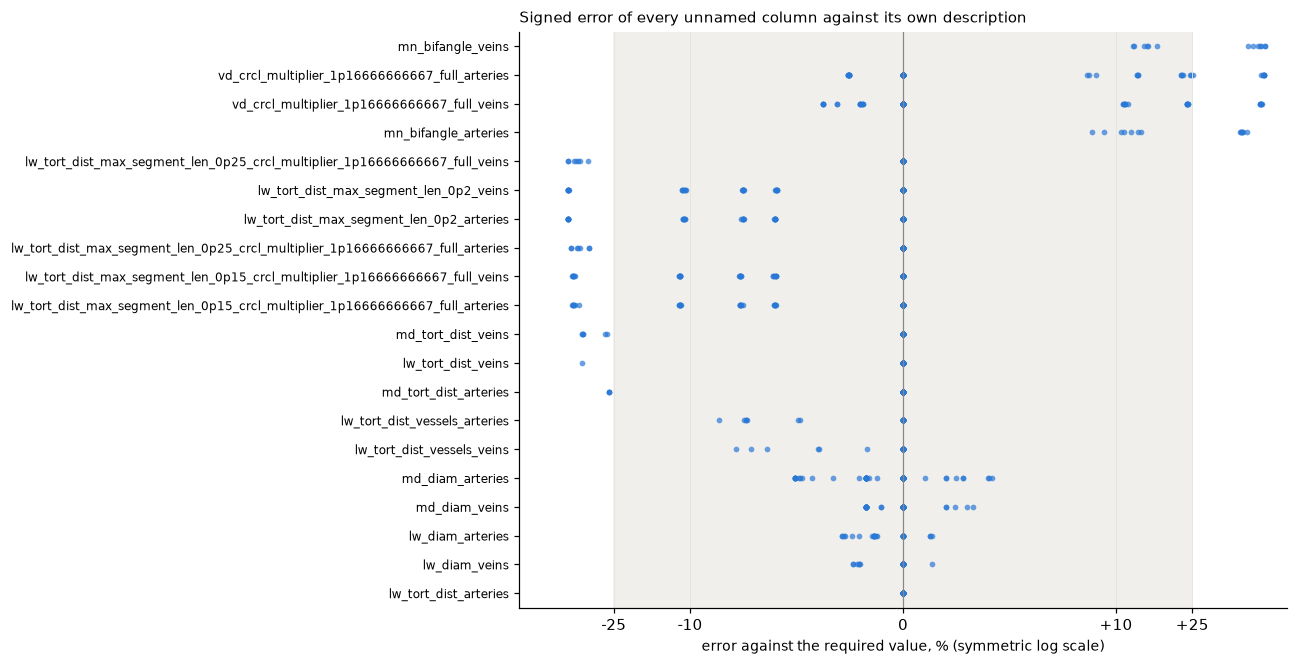

In [16]:
if not CLAIMED.empty:
    order = list(
        CLAIMED.groupby(ROW)["error"].max().sort_values(ascending=False).index
    )
    se.strips(
        CLAIMED,
        order,
        IMPLEMENTATIONS,
        "Signed error of every unnamed column against its own description",
        index=ROW,
    )
    plt.show()

## 6. The best and the worst biomarkers in this group

For each implementation, its catalogued biomarkers ordered by how close they came to the geometry,
judged by their **worst** case over every shape and angle, then by their median. *Best* lists every
biomarker inside the noise floor everywhere, and at least the closest few besides (never more than
half of what it answers). *Worst* lists, of the biomarkers out by more than 25% somewhere, the five
furthest, with the shape and angle where each was furthest.

This orders biomarkers within one program, not programs: it says which of an implementation's
numbers can be taken at face value on these shapes, and which cannot.

In [17]:
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    best, worst = se.best_and_worst(AGAINST, slug, by=ROW)
    heading(f"### 6.{number} {slug}")
    heading(f"**Best** — {len(best)} biomarker(s)")
    shown = best.copy()
    shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
    display(commented(shown))
    heading(f"**Worst** — out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere")
    if worst.empty:
        print(f"nothing it answers is out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    else:
        shown = worst.copy()
        shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
        display(commented(shown))

### 6.1 vascx

**Best** — 3 biomarker(s)

,worst,median,renderings,worst on,canonical
native,,,,,
lw_diam_crcl_multiplier_1p16666666667_full_veins,2.2%,0.0%,21,spokes-disc-centred 30°,calibre/width/vein/length-weighted
full_cre_veins,2.4%,0.0%,14,spokes-disc-centred 0°,calibre/CRE-knudtson/vein/B
lw_diam_crcl_multiplier_1p16666666667_full_arteries,2.7%,1.4%,21,spokes-macula-centred 45°,calibre/width/artery/length-weighted


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on,canonical
native,,,,,
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_arteries,43.5%,0.0%,42,koch 45°,tortuosity/hart-tau1/artery/length-weighted
lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_veins,43.4%,0.0%,42,koch 0°,tortuosity/hart-tau1/vein/length-weighted


### 6.2 Across the group

The same question asked of the group as a whole: for each canonical biomarker some member
computes, the member that came closest and its worst error. A biomarker is the group's best when
some member measures it to within the floor; its worst when even the closest member is far.

In [18]:
closest = AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
GROUP_TABLE = pd.DataFrame(
    {
        # Siblings that tie are named together: PVBM and OCULAR run the same code, so picking one
        # would credit it with a result that belongs to both.
        "closest member": closest.apply(
            lambda row: " = ".join(row.index[row == row.min()]), axis=1
        ),
        "its worst error": closest.min(axis=1),
        "members answering": closest.notna().sum(axis=1),
    }
).sort_values("its worst error")
heading(
    f"**{int((GROUP_TABLE['its worst error'] == 0).sum())} of {len(GROUP_TABLE)}** named "
    f"columns are measured to within the floor by at least one member. The closest five, then the "
    f"five furthest of those out by more than {GROUND_TRUTH_TOLERANCE:.0%} even at their closest:"
)
furthest = GROUP_TABLE[GROUP_TABLE["its worst error"] > GROUND_TRUTH_TOLERANCE].tail(5).iloc[::-1]
display(
    commented(
        pd.concat({"closest": GROUP_TABLE.drop(index=furthest.index).head(5), "furthest": furthest})
        .rename_axis(["", ROW])
        .assign(**{"its worst error": lambda t: t["its worst error"].map(se.readable)})
    )
)

**0 of 6** named columns are measured to within the floor by at least one member. The closest five, then the five furthest of those out by more than 25% even at their closest:

closest member its worst error  members answering                                    canonical
         native                                                                                                                                                                     
closest  lw_diam_crcl_multiplier_1p16666666667_full_veins                                      vascx            2.2%                  1           calibre/width/vein/length-weighted
         full_cre_veins                                                                        vascx            2.4%                  1                  calibre/CRE-knudtson/vein/B
         lw_diam_crcl_multiplier_1p16666666667_full_arteries                                   vascx            2.7%                  1         calibre/width/artery/length-weighted
         full_cre_arteries                                                                     vascx            2.9%                  1                calibre/CRE-knudtson/artery/B
furthest lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_arteries          vascx           43.5%                  1  tortuosity/hart-tau1/artery/length-weighted
         lw_tort_dist_max_segment_len_0p2_crcl_multiplier_1p16666666667_full_veins             vascx           43.4%                  1    tortuosity/hart-tau1/vein/length-weighted

## 7. Summary

Two counts per implementation, each as a fraction so its denominator is visible. Rotation can be
checked on anything that returned a number; agreement only on what has a value to agree with, by
canonical name or by its own description.

In [19]:
EVERY_ROTATION = pd.concat([se.rotation(EVIDENCE, True), se.rotation(EVIDENCE, False)])
summary = {}
for slug in IMPLEMENTATIONS:
    steady = EVERY_ROTATION.loc[slug].dropna() if slug in EVERY_ROTATION.index.get_level_values(0) else pd.Series(dtype=float)
    named = AGAINST[AGAINST["implementation"] == slug].groupby(ROW)["error"].max()
    own = CLAIMED[CLAIMED["implementation"] == slug].groupby("own")["error"].max()
    summary[slug] = {
        "move with the image": f"{int((steady > ROTATION_TOLERANCE).sum())} / {len(steady)}",
        "disagree with the geometry (canonical)": f"{int((named > GROUND_TRUTH_TOLERANCE).sum())} / {len(named)}",
        "disagree with their own description": f"{int((own > GROUND_TRUTH_TOLERANCE).sum())} / {len(own)}",
        "median error, canonical": f"{100 * AGAINST.loc[AGAINST['implementation'] == slug, 'error'].median():.1f}%",
        "exceptions": int((TROUBLES["implementation"] == slug).sum()),
        "seconds per image": round(EVIDENCE.measured[slug]["seconds"].astype(float).mean(), 1),
    }
pd.DataFrame(summary)

,vascx
move with the image,38 / 109
disagree with the geometry (canonical),2 / 6
disagree with their own description,13 / 20
"median error, canonical",0.0%
exceptions,0
seconds per image,9.3


## 8. What this group's evidence shows

*Our reading of the tables above, on the run of 2026-11-22. Every figure is one this notebook
printed; the authors' own claims are in §1.1 and are not restated as ours.*

**VascX measures little and measures it well.** It puts six canonical biomarkers in front of a
truth, 153 measurements in all, and four of them — the length-weighted artery and vein widths and
the zone-B Knudtson equivalents — are within 2.2–2.9% at worst, moving by at most 4.1% under
rotation. The other two lineages' worst errors on calibre run from 13.8% (AutoMorph's zone-B
Hubbard AVR, measured since AutoMorph's zone stage joined the benchmark on 2026-11-22) to 233%
(AutoMorph's zone-C vein width).

**Its tortuosity fails on one shape.** Length-weighted Hart τ1 is within tolerance everywhere except
the Koch curve, where it reads about 1.05 for a truth of 1.78: within a few percent of calling a
crinkled curve straight. Its two segment-capped variants, held to their own description, fail on
the same shape in the same way (41–43%). Every implementation undershoots on that shape, for the
reason the results page gives; VascX undershoots most.

**Its vessel density inside its own circle is off on one shape.** The `vd` columns claim vessel area
over a disc-centred circle of 7/6 disc diameters. That holds on every shape but `deep-bifurcation` (and one
rendering of `koch`, at 25%), where VascX reads 0.018 for arteries against the 0.011 the geometry gives (59%) and 0.026 against
0.017 for veins (57%). The cause is not diagnosed here.

**It computes far more than the six names it is judged on.** *Since 2026-11-22* this benchmark
runs both of the feature sets VascX ships for a full run, `od_centered` and the README's
recommended `full_v3`, and keeps all 132 columns they compute; 115 return a value somewhere and
109 of those have no canonical name. Most are the same few quantities — calibre, arc over chord,
curvature, density, sparsity, branching angle — over regions built on the disc-to-fovea axis:
quadrants and halves of its circle, hemifields, the ETDRS grid, an ellipse. On a synthetic shape
that axis is this benchmark's convention, so those columns are kept under VascX's names and
checked only for rotation: 36 of the 109 move by more than 10%, the worst being the hemifield and
half-circle vessel densities, which swing by up to 700% as a vessel crosses from one half to the
other, and the curvature tortuosities, by up to 505%. Every column the project page lists, with
the canonical name it is close to, in [VascX](../../docs/projects/vascx.md) §6.4.

**Its whole-image `full_v3` columns, held to the biomarker each names**, mostly agree: the
length-weighted and median widths are within 2.4–5.1%, and whole-vessel arc over chord within
8.6%; segment arc over chord fails on the Koch curve as the circle form does (37–43%). Its **mean
branching angle** does not: 29–49% out at the median and 48–60% at worst, against the angle
between the daughters the shapes are drawn with.

**Eight of its unnamed `od_centered` columns cannot be settled at all**, because they are
normalised by the disc-to-fovea distance and no shape places a fovea. The curvature-based
tortuosity among them moves by up to 494% under rotation, which is the only check it gets.

**Which to reach for:** VascX, for vessel calibre, with the caveat that its calibre is judged on
few shapes — the equivalents on the two spoke shapes, the widths on those and `deep-bifurcation`; not for tortuosity on strongly kinked vessels. Running both sets costs 9.3 s an
image.